In [1]:
print("InsightIQ is ready!")

InsightIQ is ready!


In [2]:
import pandas as pd

df = pd.read_excel("../data/Online Retail.xlsx")

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [3]:
df.shape

(541909, 8)

In [4]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
clean_df = df.copy()

In [8]:
clean_df = clean_df.dropna(subset=['CustomerID'])

In [9]:
clean_df = clean_df[clean_df['Quantity'] > 0]

In [10]:
clean_df = clean_df[clean_df['UnitPrice'] > 0]

In [11]:
clean_df['CustomerID'] = clean_df['CustomerID'].astype(int)

In [12]:
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'])

In [13]:
clean_df['Revenue'] = (
    clean_df['Quantity'] * clean_df['UnitPrice']
)

In [14]:
clean_df['Year'] = clean_df['InvoiceDate'].dt.year
clean_df['Month'] = clean_df['InvoiceDate'].dt.month
clean_df['Month_Name'] = clean_df['InvoiceDate'].dt.month_name()
clean_df['Day'] = clean_df['InvoiceDate'].dt.day
clean_df['Day_Name'] = clean_df['InvoiceDate'].dt.day_name()

In [15]:
clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_Name,Day,Day_Name
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,December,1,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,December,1,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday


In [16]:
clean_df.shape

(397884, 14)

In [17]:
total_revenue = clean_df['Revenue'].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £8,911,407.90


In [18]:
customers = clean_df['CustomerID'].nunique()

print(f"Total Customers: {customers:,}")

Total Customers: 4,338


In [19]:
orders = clean_df['InvoiceNo'].nunique()

print(f"Total Orders: {orders:,}")

Total Orders: 18,532


In [20]:
products = clean_df['Description'].nunique()

print(f"Total Products: {products:,}")

Total Products: 3,877


In [21]:
monthly_revenue = (
    clean_df
    .groupby(['Year', 'Month'])['Revenue']
    .sum()
    .reset_index()
)

monthly_revenue

,Year,Month,Revenue
0,2010,12,572713.890
1,2011,1,569445.040
2,2011,2,447137.350
3,2011,3,595500.760
4,2011,4,469200.361
5,2011,5,678594.560
6,2011,6,661213.690
7,2011,7,600091.011
8,2011,8,645343.900
9,2011,9,952838.382


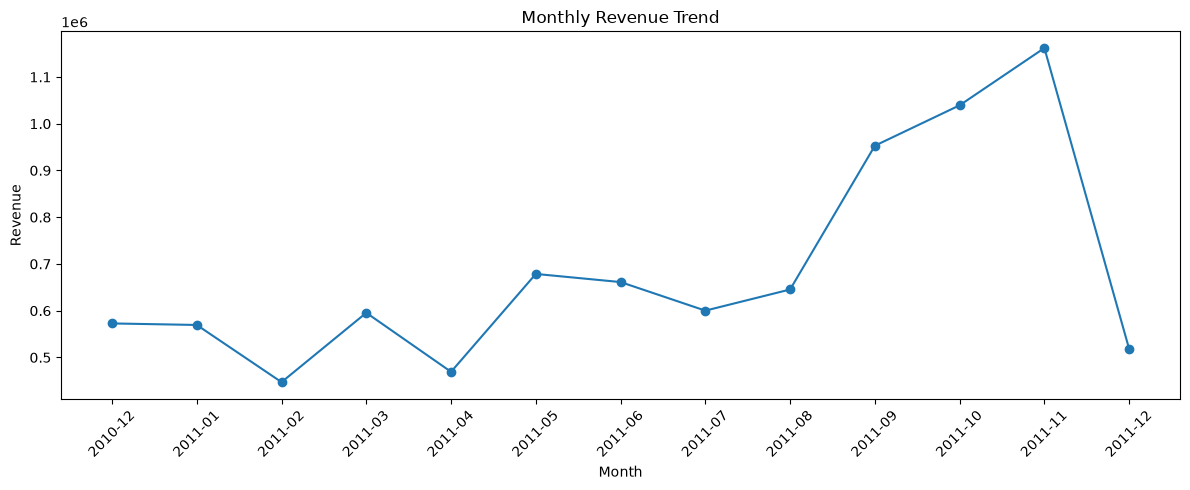

In [22]:
import matplotlib.pyplot as plt

monthly_revenue['Period'] = (
    monthly_revenue['Year'].astype(str)
    + '-'
    + monthly_revenue['Month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['Period'],
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
top_products = (
    clean_df
    .groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100448.15
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68844.33
ASSORTED COLOUR BIRD ORNAMENT          56580.34
Manual                                 53779.93
RABBIT NIGHT LIGHT                     51346.20
Name: Revenue, dtype: float64

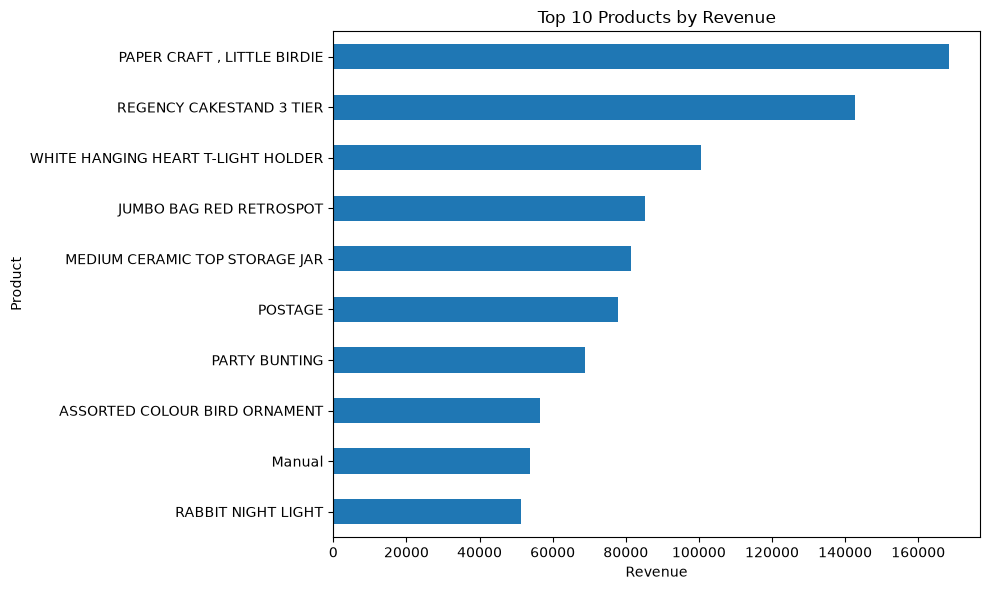

In [24]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [25]:
country_revenue = (
    clean_df
    .groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_revenue

Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64

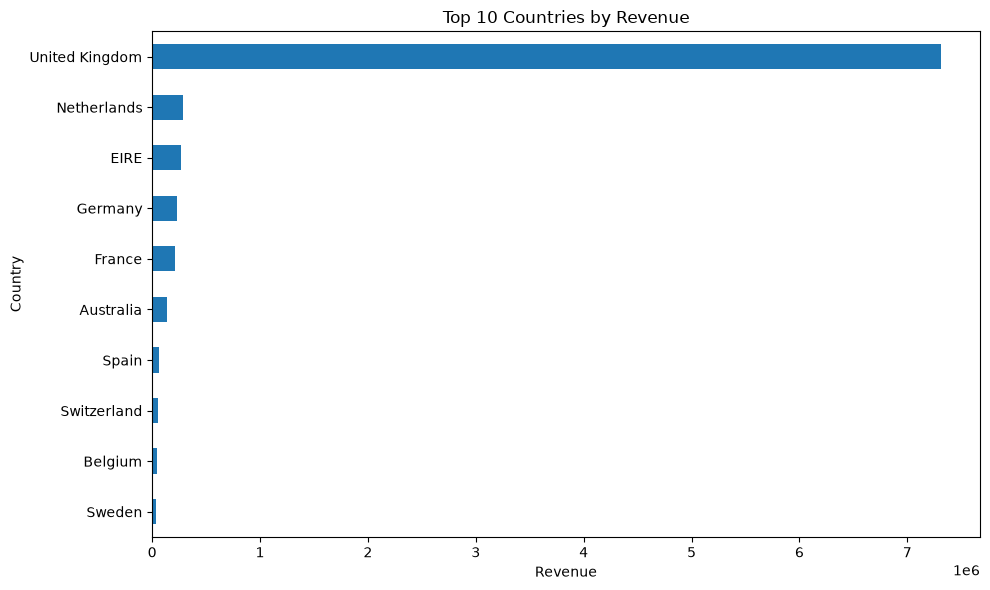

In [26]:
plt.figure(figsize=(10, 6))

country_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [27]:
import sqlite3

conn = sqlite3.connect("../insightiq.db")

clean_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully!")

Database created successfully!


In [28]:
query = """
SELECT *
FROM sales
LIMIT 5;
"""

sql_result = pd.read_sql_query(query, conn)

sql_result

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_Name,Day,Day_Name
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,December,1,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,December,1,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,1,Wednesday


In [31]:
query = """
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
GROUP BY CustomerID
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, conn)

top_customers

,CustomerID,total_revenue
0,14646,280206.02
1,18102,259657.30
2,17450,194550.79
3,16446,168472.50
4,14911,143825.06
5,12415,124914.53
6,14156,117379.63
7,17511,91062.38
8,16029,81024.84
9,12346,77183.60


In [32]:
query = """
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
GROUP BY Description
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, conn)

top_products

,Description,total_revenue
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,142592.95
2,WHITE HANGING HEART T-LIGHT HOLDER,100448.15
3,JUMBO BAG RED RETROSPOT,85220.78
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
5,POSTAGE,77803.96
6,PARTY BUNTING,68844.33
7,ASSORTED COLOUR BIRD ORNAMENT,56580.34
8,Manual,53779.93
9,RABBIT NIGHT LIGHT,51346.20


In [33]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
GROUP BY Country
ORDER BY total_revenue DESC;
"""

country_revenue = pd.read_sql_query(query, conn)

country_revenue

,Country,total_revenue
0,United Kingdom,7308391.55
1,Netherlands,285446.34
2,EIRE,265545.90
3,Germany,228867.14
4,France,209024.05
5,Australia,138521.31
6,Spain,61577.11
7,Switzerland,56443.95
8,Belgium,41196.34
9,Sweden,38378.33


In [34]:
query = """
SELECT
    Year,
    Month,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
GROUP BY Year, Month
ORDER BY Year, Month;
"""

monthly_revenue = pd.read_sql_query(query, conn)

monthly_revenue

,Year,Month,total_revenue
0,2010,12,572713.89
1,2011,1,569445.04
2,2011,2,447137.35
3,2011,3,595500.76
4,2011,4,469200.36
5,2011,5,678594.56
6,2011,6,661213.69
7,2011,7,600091.01
8,2011,8,645343.90
9,2011,9,952838.38


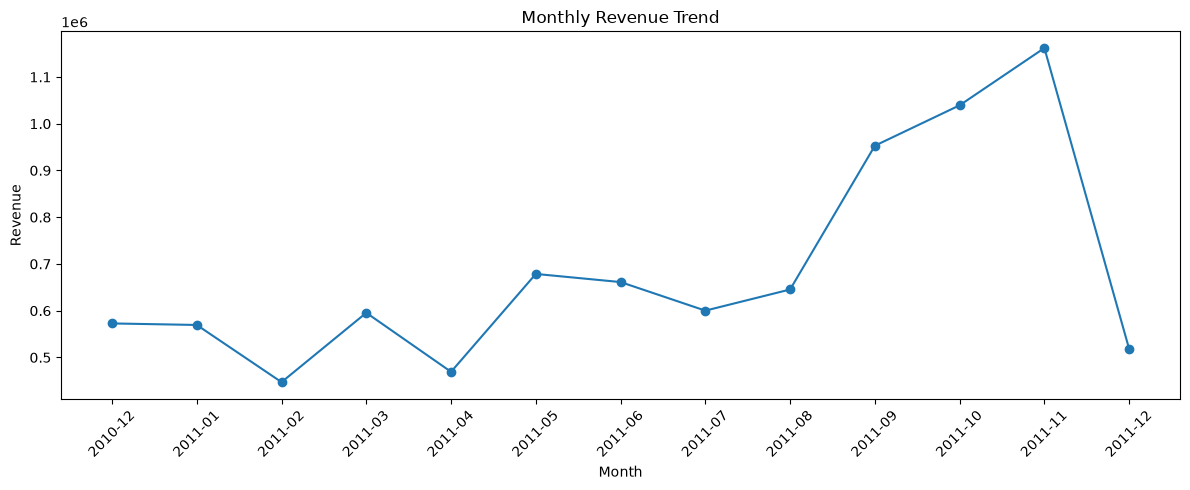

In [36]:
import matplotlib.pyplot as plt

monthly_revenue['Period'] = (
    monthly_revenue['Year'].astype(str)
    + '-'
    + monthly_revenue['Month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['Period'],
    monthly_revenue['total_revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
query = """
SELECT
    ROUND(
        SUM(Revenue) / COUNT(DISTINCT InvoiceNo),
        2
    ) AS average_order_value
FROM sales;
"""

average_order_value = pd.read_sql_query(query, conn)

average_order_value

,average_order_value
0,480.87


In [38]:
query = """
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS customer_revenue,
    ROUND(
        SUM(Revenue) * 100.0 /
        (SELECT SUM(Revenue) FROM sales),
        2
    ) AS revenue_percentage
FROM sales
GROUP BY CustomerID
ORDER BY customer_revenue DESC;
"""

customer_contribution = pd.read_sql_query(query, conn)

customer_contribution.head(10)

,CustomerID,customer_revenue,revenue_percentage
0,14646,280206.02,3.14
1,18102,259657.30,2.91
2,17450,194550.79,2.18
3,16446,168472.50,1.89
4,14911,143825.06,1.61
5,12415,124914.53,1.40
6,14156,117379.63,1.32
7,17511,91062.38,1.02
8,16029,81024.84,0.91
9,12346,77183.60,0.87


In [39]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

In [40]:
snapshot_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = clean_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [41]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [42]:
features = ['Recency', 'Frequency', 'Monetary']

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm[features])

rfm_scaled[:5]

array([[ 2.33457414, -0.4250965 ,  8.35866818],
       [-0.90534032,  0.3544168 ,  0.25096626],
       [-0.17535959, -0.03533985, -0.02859601],
       [-0.73534481, -0.4250965 , -0.0330118 ],
       [ 2.17457836, -0.4250965 , -0.19134727]])

In [43]:
inertia = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

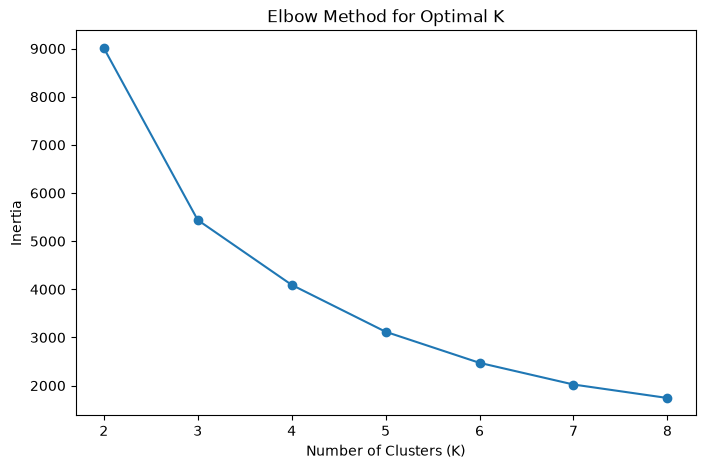

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.show()

In [45]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [46]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,0
3,12349,19,1,1757.55,0
4,12350,310,1,334.40,1


In [47]:
cluster_summary = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,3054,43.70,3.68,1359.05
1,1067,248.08,1.55,480.62
2,13,7.38,82.54,127338.31
3,204,15.50,22.33,12709.09


In [48]:
segment_mapping = {
    0: "Potential / Occasional",
    1: "At Risk",
    2: "VIP / Champions",
    3: "High-Value Loyal"
}

rfm['Segment'] = rfm['Cluster'].map(segment_mapping)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,High-Value Loyal
1,12347,2,7,4310.00,0,Potential / Occasional
2,12348,75,4,1797.24,0,Potential / Occasional
3,12349,19,1,1757.55,0,Potential / Occasional
4,12350,310,1,334.40,1,At Risk


In [49]:
segment_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

segment_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,
At Risk,1067,248.08,1.55,480.62
High-Value Loyal,204,15.50,22.33,12709.09
Potential / Occasional,3054,43.70,3.68,1359.05
VIP / Champions,13,7.38,82.54,127338.31


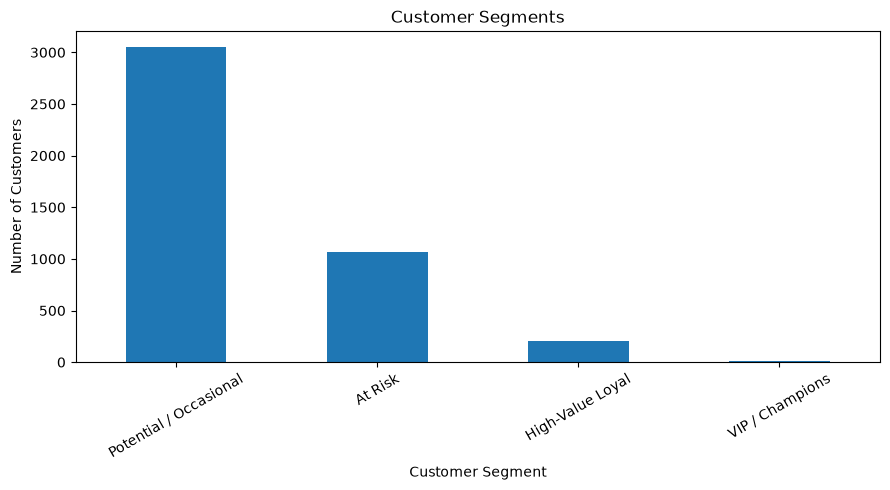

In [50]:
segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(9, 5))

segment_counts.plot(kind='bar')

plt.title('Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [51]:
segment_revenue = (
    rfm.groupby('Segment')['Monetary']
    .sum()
    .sort_values(ascending=False)
)

segment_revenue

Segment
Potential / Occasional    4150536.513
High-Value Loyal          2592654.460
VIP / Champions           1655398.080
At Risk                    512818.851
Name: Monetary, dtype: float64

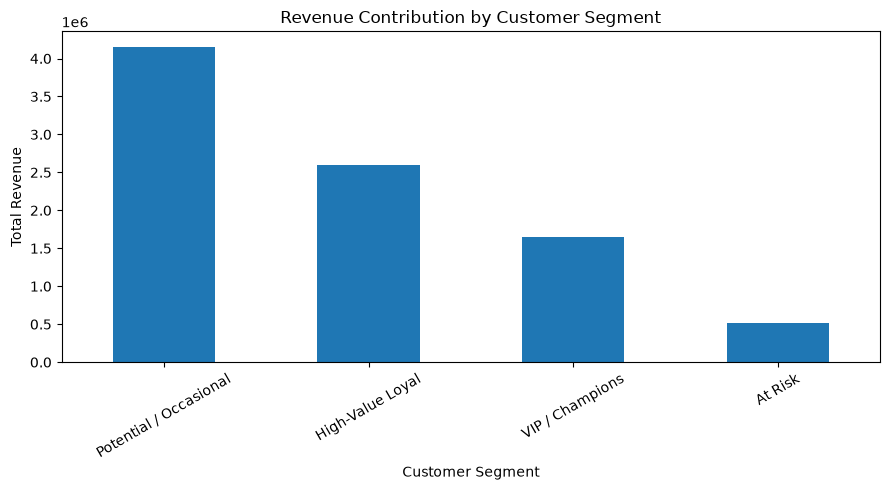

In [52]:
plt.figure(figsize=(9, 5))

segment_revenue.plot(kind='bar')

plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Revenue')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [53]:
# Define a cutoff date
cutoff_date = pd.Timestamp('2011-09-30')

# Historical data used to build customer features
historical_df = clean_df[
    clean_df['InvoiceDate'] <= cutoff_date
].copy()

# Future period used to define the target
future_df = clean_df[
    clean_df['InvoiceDate'] > cutoff_date
].copy()

print("Historical records:", len(historical_df))
print("Future records:", len(future_df))

Historical records: 265042
Future records: 132842


In [54]:
prediction_data = historical_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda x: (cutoff_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

prediction_data.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,254,1,77183.60
1,12347,58,5,2790.86
2,12348,4,4,1797.24
3,12350,239,1,334.40
4,12352,1,7,2194.31


In [55]:
future_customers = set(future_df['CustomerID'].unique())

prediction_data['Purchased_Again'] = (
    prediction_data['CustomerID']
    .isin(future_customers)
    .astype(int)
)

prediction_data.head()

,CustomerID,Recency,Frequency,Monetary,Purchased_Again
0,12346,254,1,77183.60,0
1,12347,58,5,2790.86,1
2,12348,4,4,1797.24,0
3,12350,239,1,334.40,0
4,12352,1,7,2194.31,1


In [56]:
prediction_data['Purchased_Again'].value_counts()

Purchased_Again
1    1846
0    1758
Name: count, dtype: int64

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

X = prediction_data[
    ['Recency', 'Frequency', 'Monetary']
]

y = prediction_data['Purchased_Again']

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [59]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [60]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6144244105409153


In [61]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.61      0.61      0.61       352
           1       0.62      0.62      0.62       369

    accuracy                           0.61       721
   macro avg       0.61      0.61      0.61       721
weighted avg       0.61      0.61      0.61       721



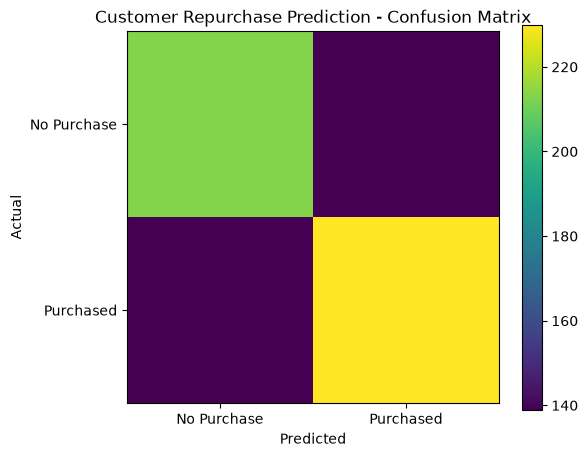

In [62]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title('Customer Repurchase Prediction - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.colorbar()

plt.xticks([0, 1], ['No Purchase', 'Purchased'])
plt.yticks([0, 1], ['No Purchase', 'Purchased'])

plt.show()

In [63]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
)

feature_importance

,Feature,Importance
2,Monetary,0.510335
0,Recency,0.366331
1,Frequency,0.123334


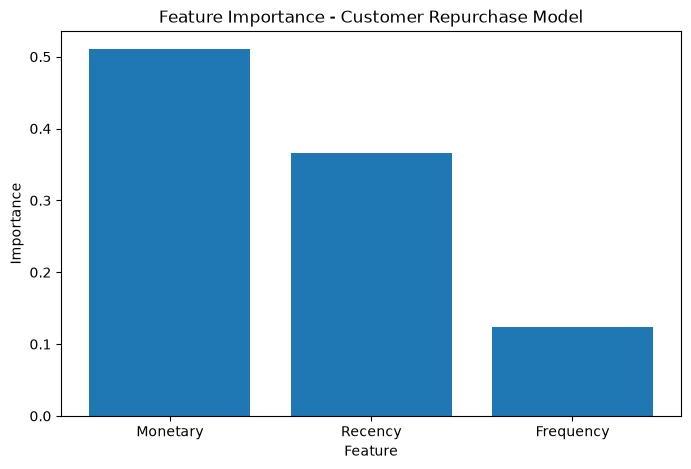

In [64]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title('Feature Importance - Customer Repurchase Model')
plt.xlabel('Feature')
plt.ylabel('Importance')

plt.show()

In [65]:
import joblib

joblib.dump(
    model,
    "../models/customer_repurchase_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [66]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6144244105409153
              precision    recall  f1-score   support

           0       0.61      0.61      0.61       352
           1       0.62      0.62      0.62       369

    accuracy                           0.61       721
   macro avg       0.61      0.61      0.61       721
weighted avg       0.61      0.61      0.61       721



In [67]:
enhanced_features = historical_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda x: (cutoff_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Unique_Products=('StockCode', 'nunique'),
    First_Purchase=('InvoiceDate', 'min')
).reset_index()

enhanced_features['Customer_Tenure'] = (
    cutoff_date - enhanced_features['First_Purchase']
).dt.days

enhanced_features['Avg_Order_Value'] = (
    enhanced_features['Monetary'] /
    enhanced_features['Frequency']
)

enhanced_features.head()

,CustomerID,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,First_Purchase,Customer_Tenure,Avg_Order_Value
0,12346,254,1,77183.60,74215,1,2011-01-18 10:01:00,254,77183.600000
1,12347,58,5,2790.86,1590,82,2010-12-07 14:57:00,296,558.172000
2,12348,4,4,1797.24,2341,22,2010-12-16 19:09:00,287,449.310000
3,12350,239,1,334.40,197,17,2011-02-02 16:01:00,239,334.400000
4,12352,1,7,2194.31,409,47,2011-02-16 12:33:00,225,313.472857


In [68]:
feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Total_Quantity',
    'Unique_Products',
    'Customer_Tenure',
    'Avg_Order_Value'
]

X = enhanced_features[feature_columns]
y = enhanced_features['Purchased_Again']

KeyError: 'Purchased_Again'

In [69]:
enhanced_features['Purchased_Again'] = (
    enhanced_features['CustomerID']
    .isin(future_customers)
    .astype(int)
)

enhanced_features.head()

,CustomerID,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,First_Purchase,Customer_Tenure,Avg_Order_Value,Purchased_Again
0,12346,254,1,77183.60,74215,1,2011-01-18 10:01:00,254,77183.600000,0
1,12347,58,5,2790.86,1590,82,2010-12-07 14:57:00,296,558.172000,1
2,12348,4,4,1797.24,2341,22,2010-12-16 19:09:00,287,449.310000,0
3,12350,239,1,334.40,197,17,2011-02-02 16:01:00,239,334.400000,0
4,12352,1,7,2194.31,409,47,2011-02-16 12:33:00,225,313.472857,1


In [70]:
enhanced_features.columns

Index(['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Total_Quantity',
       'Unique_Products', 'First_Purchase', 'Customer_Tenure',
       'Avg_Order_Value', 'Purchased_Again'],
      dtype='str')

In [71]:
feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Total_Quantity',
    'Unique_Products',
    'Customer_Tenure',
    'Avg_Order_Value'
]

X = enhanced_features[feature_columns]

y = enhanced_features['Purchased_Again']

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Total_Quantity',
    'Unique_Products',
    'Customer_Tenure',
    'Avg_Order_Value'
]

X = enhanced_features[feature_columns]
y = enhanced_features['Purchased_Again']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (3604, 7)
Target: (3604,)


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2883
Testing records: 721


In [75]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [76]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.6823855755894591

              precision    recall  f1-score   support

           0       0.67      0.70      0.68       352
           1       0.70      0.66      0.68       369

    accuracy                           0.68       721
   macro avg       0.68      0.68      0.68       721
weighted avg       0.68      0.68      0.68       721



In [77]:
feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
)

feature_importance

,Feature,Importance
2,Monetary,0.165792
0,Recency,0.161832
4,Unique_Products,0.160519
1,Frequency,0.142562
3,Total_Quantity,0.138191
6,Avg_Order_Value,0.120607
5,Customer_Tenure,0.110496


In [78]:
import joblib

joblib.dump(
    model,
    "../models/customer_repurchase_model.pkl"
)

print("Improved model saved successfully!")

Improved model saved successfully!


In [79]:
clean_df.to_csv(
    "../data/clean_sales.csv",
    index=False
)

print("clean_sales.csv created successfully!")

clean_sales.csv created successfully!


In [80]:
rfm.to_csv(
    "../data/customer_segments.csv",
    index=False
)

print("customer_segments.csv created successfully!")

customer_segments.csv created successfully!


In [81]:
rfm_export = rfm[
    [
        'CustomerID',
        'Recency',
        'Frequency',
        'Monetary',
        'Cluster',
        'Segment'
    ]
].drop_duplicates(subset=['CustomerID'])

rfm_export.to_csv(
    "../data/customer_segments.csv",
    index=False
)

print("Rows:", len(rfm_export))
print("Unique customers:", rfm_export['CustomerID'].nunique())

Rows: 4338
Unique customers: 4338


In [82]:
# Export model performance for Power BI

model_metrics = pd.DataFrame({
    'Metric': ['Accuracy'],
    'Value': [0.68]
})

feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': model.feature_importances_
})

model_metrics.to_csv("../data/model_metrics.csv", index=False)
feature_importance.to_csv("../data/feature_importance.csv", index=False)

print("Model files exported successfully!")

Model files exported successfully!


In [83]:
from sklearn.metrics import precision_score, recall_score, f1_score

prediction_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ]
})

prediction_metrics.to_csv(
    "../data/prediction_metrics.csv",
    index=False
)

print("Prediction metrics exported!")

Prediction metrics exported!
